In [1]:
from requirements import *

# Figure 4


In [2]:
adata_cite = sc.read_h5ad(CITE)
adata_xenv2 = sc.read_h5ad(XEN_V2)

## Figure 4a. Lymphocyte subset frequency by group (Control / MDS / MDS Aza / MDS Post Allo)


<Figure size 320x320 with 0 Axes>

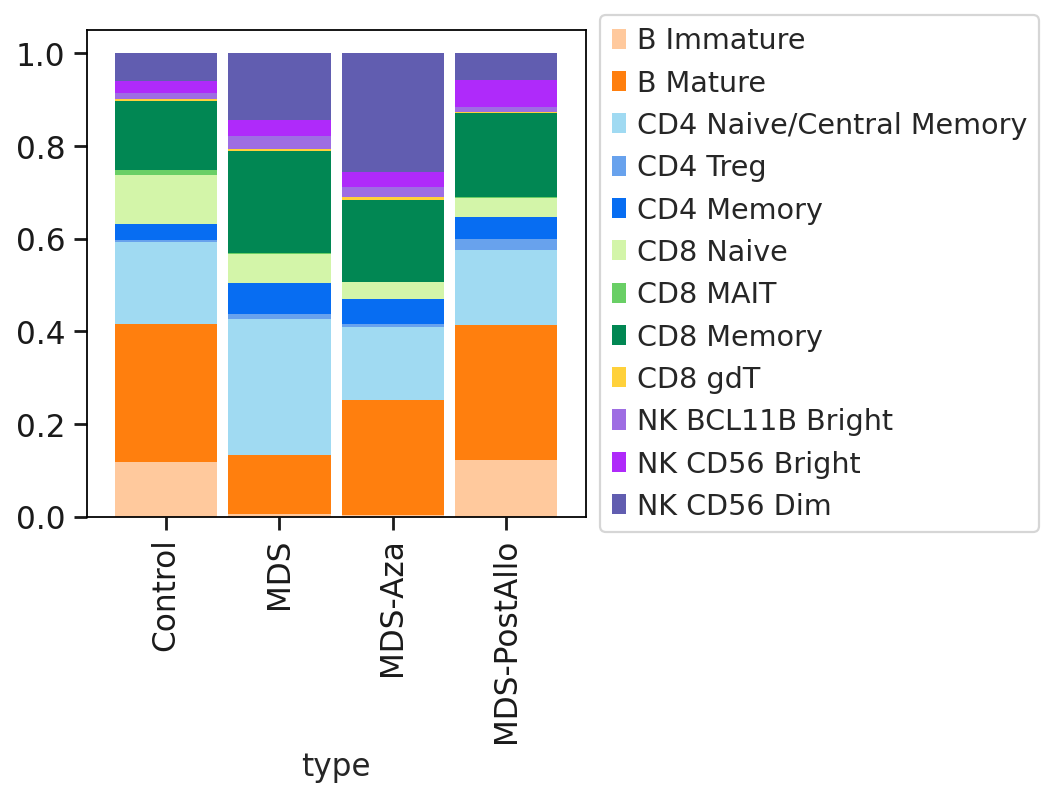

In [3]:
sc.set_figure_params(figsize=(4, 4))
f = plt.figure()

tmp = adata_cite[(adata_cite.obs['ct_general'].isin(['T Cell', 'B Cell','NK']))]
tmp.obs['type'] = [str(x) for x in tmp.obs['type']]
tmp.obs['ct_tmp'] = [str(x) for x in tmp.obs['ct_refined']]
tmp.obs['ct_tmp'][tmp.obs['ct_refined'].isin(['CD8 Effector Memory', 'CD8 Memory GZMK+','CD8 Memory TOX+', 'CD8 TEMRA GZMB+', 'CD8 TEMRA ISG+'])] = 'CD8 Memory'
tmp.obs['ct_tmp'][tmp.obs['ct_refined'].isin(['CD4 FOXO1+', 'CD4 Memory'])] = 'CD4 Memory'
tmp.obs['type'][tmp.obs['type'].isin(['MDS-EB1','MDS-EB2'])] = 'MDS'
df = pd.crosstab(index=tmp.obs['type'], columns=tmp.obs['ct_tmp']).apply(lambda x: x/x.sum(), axis=1)
df = df.reindex(['Control','MDS','MDS-Aza','MDS-PostAllo'])
df = df[['B Immature','B Mature','CD4 Naive/Central Memory','CD4 Treg','CD4 Memory','CD8 Naive','CD8 MAIT','CD8 Memory','CD8 gdT','NK BCL11B Bright','NK CD56 Bright','NK CD56 Dim']]


cmp = matplotlib.colors.ListedColormap(["#ffc99d", "#ff7f0e", 
                                        "#a0daf2", "#68a2ed","#076df2",
                                        '#d3f5a9','#69cf65','#018753','#ffd13b',
                                        '#9e6de3','#af2afa','#615db0'])
g = df.plot(kind='bar', stacked=True, width = 0.9,colormap= cmp,edgecolor='none')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), ncol=1)
plt.grid(False)
plt.tick_params( bottom=True, left = True)
plt.show()


## Figure 4b. CD8 TCR clone-size categories, Control vs MDS

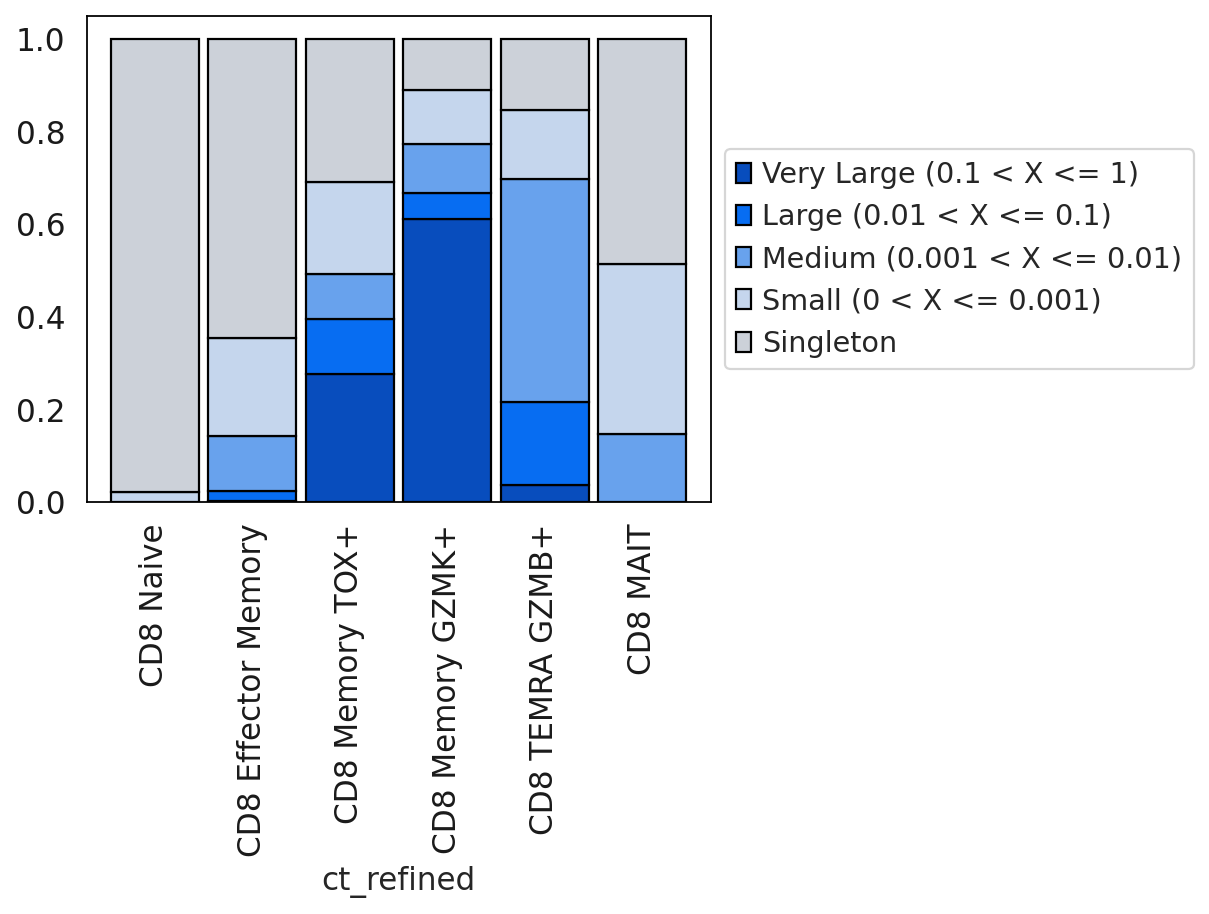

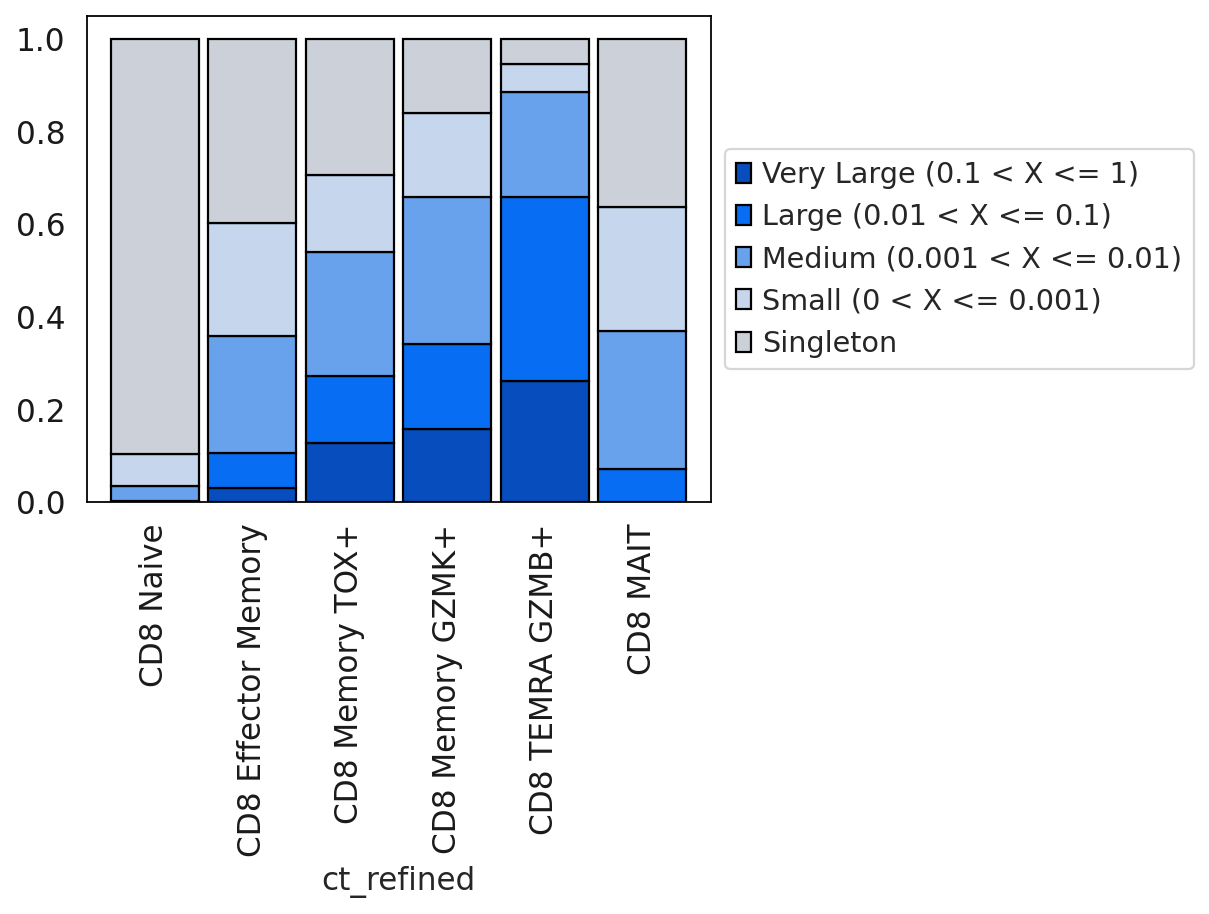

In [4]:
sc.set_figure_params(figsize=(5, 4))

cts = ['CD8 TEMRA GZMB+','CD8 Naive','CD8 Effector Memory','CD8 Memory GZMK+','CD8 Memory TOX+','CD8 MAIT','CD8 TEMRA ISG+']
tmp = adata_cite[(adata_cite.obs['ct_refined'].isin(cts))]
tmp.obs['ct_refined'][tmp.obs['ct_refined'] == 'CD8 TEMRA ISG+'] = 'CD8 TEMRA GZMB+'
tmp.obs['tcr_size_prop'] = [str(x) for x in tmp.obs['tcr_size_prop']]
tmp.obs['tcr_size_prop'][tmp.obs['tcr_size_prop'] == 'Hyperexpanded (0.1 < X <= 1)'] = 'Very Large (0.1 < X <= 1)'
tmp =tmp[~(tmp.obs['tcr_size_prop'] == 'Unassigned')]


ad_ctl = tmp[(tmp.obs['type'].isin(['Control']))]
df = pd.crosstab(index=ad_ctl.obs['ct_refined'], columns=ad_ctl.obs['tcr_size_prop'])
df = df.reindex(['CD8 Naive', 'CD8 Effector Memory', 'CD8 Memory TOX+', 'CD8 Memory GZMK+', 'CD8 TEMRA GZMB+', 'CD8 MAIT'])#,'CD4 Naive','CD4 Memory','CD4 FOXO1+','CD4 Treg'])
df = df[['Very Large (0.1 < X <= 1)', 'Large (0.01 < X <= 0.1)', 'Medium (0.001 < X <= 0.01)', 'Small (0 < X <= 0.001)', 'Singleton']]
cmp = matplotlib.colors.ListedColormap(['#084dbd',"#076df2",  "#68a2ed","#c5d6ed", '#ccd1d9'])
df.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9,colormap= cmp,edgecolor='black')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()


ad_mds = tmp[(tmp.obs['type'].isin(['MDS','MDS-EB1','MDS-EB2']))]
df = pd.crosstab(index=ad_mds.obs['ct_refined'], columns=ad_mds.obs['tcr_size_prop'])
df = df.reindex(['CD8 Naive', 'CD8 Effector Memory', 'CD8 Memory TOX+', 'CD8 Memory GZMK+', 'CD8 TEMRA GZMB+', 'CD8 MAIT'])#,'CD4 Naive','CD4 Memory','CD4 FOXO1+','CD4 Treg'])
df = df[['Very Large (0.1 < X <= 1)', 'Large (0.01 < X <= 0.1)', 'Medium (0.001 < X <= 0.01)', 'Small (0 < X <= 0.001)', 'Singleton']]
df.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9,colormap= cmp,edgecolor='black')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()



## Figure 4c. Xenium TCR-panel cell-type UMAP

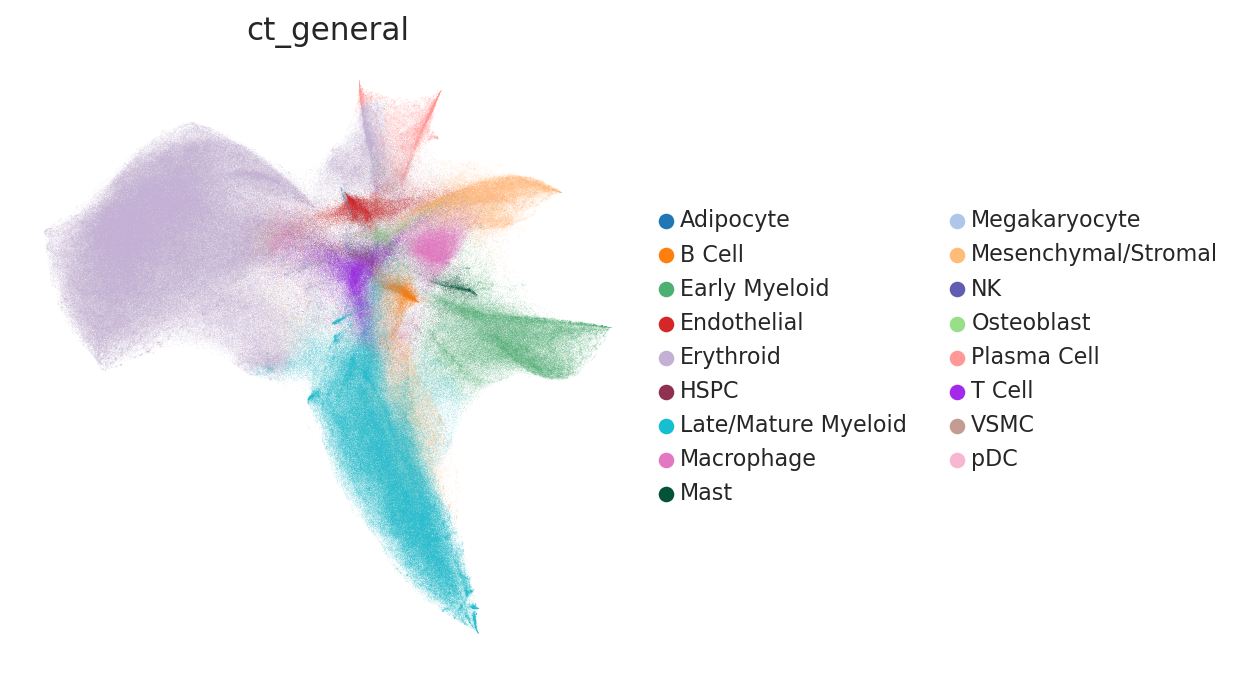

In [5]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.umap(adata_xenv2,color= ['ct_general'],
          frameon=False, wspace=0.6, ncols=2,vmin = 1, vmax =2, sort_order = True,
            legend_fontsize =10,palette={ "T Cell":"#a42aeb", "B Cell": "#ff7f0e", "NK": "#ffffff", "Plasma Cell": "#ff9896", 
         "Early Myeloid": "#4db073", "Late/Mature Myeloid": "#17becf", "Macrophage": "#e377c2", "Mast": "#035239",
         "pDC": "#f7b6d2", "Megakaryocyte": "#aec7e8",
        "Adipocyte": "#1f77b4", "VSMC": "#c49c94", "Mesenchymal/Stromal": "#ffbb78", 
         "Osteoblast": "#98df8a",
         "Endothelial": "#d62728", 
         "Erythroid":"#c5b0d5", "HSPC": '#8f3251', "NK": '#615db0'})


## Figure 4g. Xenium Mutant probe QC

In [6]:
probe_di = {'SRSF2': ['NM_001195427_ALT_283:'], 'IDH1': ['NM_005896_ALT_394:A'],
            'U2AF1': ['NM_006758_ALT_100:T'],
           'SF3B1': ['NM_012433_ALT_2097:G', 'ORAI2_e1_alt_e2', 'ZDHHC16_e9_alt_e10'],
           'ASXL1': ['NM_015338_ALT_1899:'], 'DNMT3A': ['NM_022552_ALT_1237:GG', 'NM_022552_ALT_1875:'],
           'CUX1': ['NM_181552_ALT_364:TT']}

sample_mutation_di = {'U2AF1': ['region1_0033266','region1_0065644','region2_0065644','region1_0065647','region2_0065647'], 'ASXL1': ['region1_0033266'],
                      'IDH1': ['region1_0033082'], 'SRSF2': ['region1_0033082'], 'CUX1': ['region1_0033082'],
                      'DNMT3A': ['region1_0033134'], 'SF3B1': ['region1_0033274', 'region1_0033485', 'region2_0043245', 'region2_0043233', 'region1_0065586']}

df_probe = None
for mutation in probe_di:
    mutsamples = sample_mutation_di[mutation]
    print(mutsamples)
    for probe in probe_di[mutation]:
        print(probe)
        df = sc.get.obs_df(adata_xenv2, keys=[probe, 'sample_name', 'ct_general'], use_raw= True)
        df = df.iloc[:,0:2]
        df.columns = ['mut','sample']
        cutoff = []
        fpr = []
        num = []
        for i in range(int(max(df['mut']) + 1)):
            print(i)
            cutoff.append(str(i))
            num.append(sum(df.loc[df['sample'].isin(mutsamples)]['mut'] >= i))
            if sum(df.loc[df['sample'].isin(mutsamples)]['mut'] >= i) == 0:
                fpr.append(1)
            else:
                expected_falsepos = (sum(df.loc[~(df['sample'].isin(mutsamples))]['mut'] >= i)/df.loc[~(df['sample'].isin(mutsamples))].shape[0]) * df.loc[df['sample'].isin(mutsamples)].shape[0]
                val = expected_falsepos/sum(df.loc[df['sample'].isin(mutsamples)]['mut'] >= i) # proportion of positives that are expected to be false positives
                fpr.append(min(val,1))
        currdf = pd.DataFrame(list(zip(cutoff, fpr, num)),columns=['Probe Quantity Cutoff', 'Predicted FDR', 'Mutant Cells'])
        currdf['Mutant Probe'] = probe
        currdf['Mutation'] = mutation
        df_probe = pd.concat([df_probe, currdf])

df_probe.reset_index(drop=True, inplace=True)
df_probe['cutoff'] = [int(x) for x in df_probe['Probe Quantity Cutoff']]
df_probe['log10(Mutant Cells)'] = np.log10(df_probe['Mutant Cells'])


['region1_0033082']
NM_001195427_ALT_283:
0
1
2
3
['region1_0033082']
NM_005896_ALT_394:A
0
1
2
['region1_0033266', 'region1_0065644', 'region2_0065644', 'region1_0065647', 'region2_0065647']
NM_006758_ALT_100:T
0
1
2
3
4
['region1_0033274', 'region1_0033485', 'region2_0043245', 'region2_0043233', 'region1_0065586']
NM_012433_ALT_2097:G
0
1
2
3
4
5
6
7
ORAI2_e1_alt_e2
0
1
2
3
ZDHHC16_e9_alt_e10
0
1
2
['region1_0033266']
NM_015338_ALT_1899:
0
1
2
3
['region1_0033134']
NM_022552_ALT_1237:GG
0
1
NM_022552_ALT_1875:
0
1
2
3
4
5
6
7
8
9
['region1_0033082']
NM_181552_ALT_364:TT
0
1
2
3


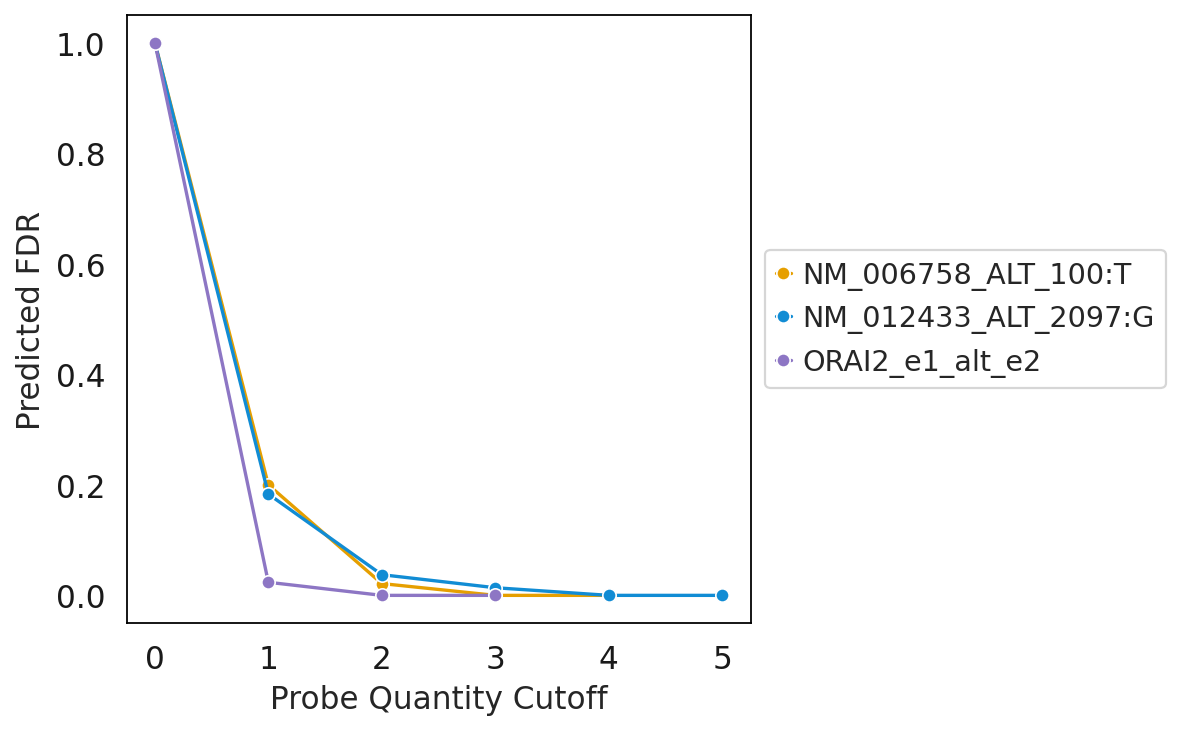

In [7]:
df_probe = df_probe[df_probe['Mutant Probe'].isin(['NM_006758_ALT_100:T','NM_012433_ALT_2097:G','ORAI2_e1_alt_e2'])]
cmp = ["#E69F00", "#118cd4", "#8d76c4"]
df_probe = df_probe[df_probe['cutoff'] <= 5]
sns.lineplot(data=df_probe, x="Probe Quantity Cutoff", y="Predicted FDR", hue = 'Mutant Probe', marker='o', palette = cmp)
plt.grid(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()

In [8]:
df_probe

,Probe Quantity Cutoff,Predicted FDR,Mutant Cells,Mutant Probe,Mutation,cutoff,log10(Mutant Cells)
7,0,1.000000,502779,NM_006758_ALT_100:T,U2AF1,0,5.701377
8,1,0.200029,3960,NM_006758_ALT_100:T,U2AF1,1,3.597695
9,2,0.021347,93,NM_006758_ALT_100:T,U2AF1,2,1.968483
10,3,0.000000,5,NM_006758_ALT_100:T,U2AF1,3,0.698970
11,4,0.000000,2,NM_006758_ALT_100:T,U2AF1,4,0.301030
12,0,1.000000,987983,NM_012433_ALT_2097:G,SF3B1,0,5.994749
13,1,0.183338,38822,NM_012433_ALT_2097:G,SF3B1,1,4.589078
14,2,0.037410,2333,NM_012433_ALT_2097:G,SF3B1,2,3.367915
15,3,0.013824,183,NM_012433_ALT_2097:G,SF3B1,3,2.262451
16,4,0.000000,17,NM_012433_ALT_2097:G,SF3B1,4,1.230449
